In [1]:
!pip install python-docx

In [2]:
import docx

def read_docx(file_path):
    doc = docx.Document(file_path)
    fullText = []
    for para in doc.paragraphs:
        fullText.append(para.text)
    return '\n'.join(fullText)

task_text = read_docx('/content/Lab8_Task.docx')
print("--- Document Content ---")
print(task_text)

--- Document Content ---
Objective
Apply and compare edge detection methods using Python and OpenCV, and investigate how parameter changes affect the detected edges.
Task 1: Apply Edge Detection Methods
Select a new image of your choice. Do not use the image provided in the original notebook.
Apply the following methods to your selected image using the provided notebook as a reference:
Sobel Edge Detector
Prewitt Edge Detector
Canny Edge Detector
Display the original image and the three resulting edge maps.
Task 2: Investigate the Effect of Canny Thresholds
Apply Canny edge detection using the following threshold pairs:
Low = 30, High = 90
Low = 50, High = 150
Low = 100, High = 200
Display the three resulting edge maps side by side.
Explain how changing the thresholds affects the number of detected edges and the visibility of image details.
Submission Requirements
Submit your solution as a Jupyter Notebook (.ipynb) file and PDF.



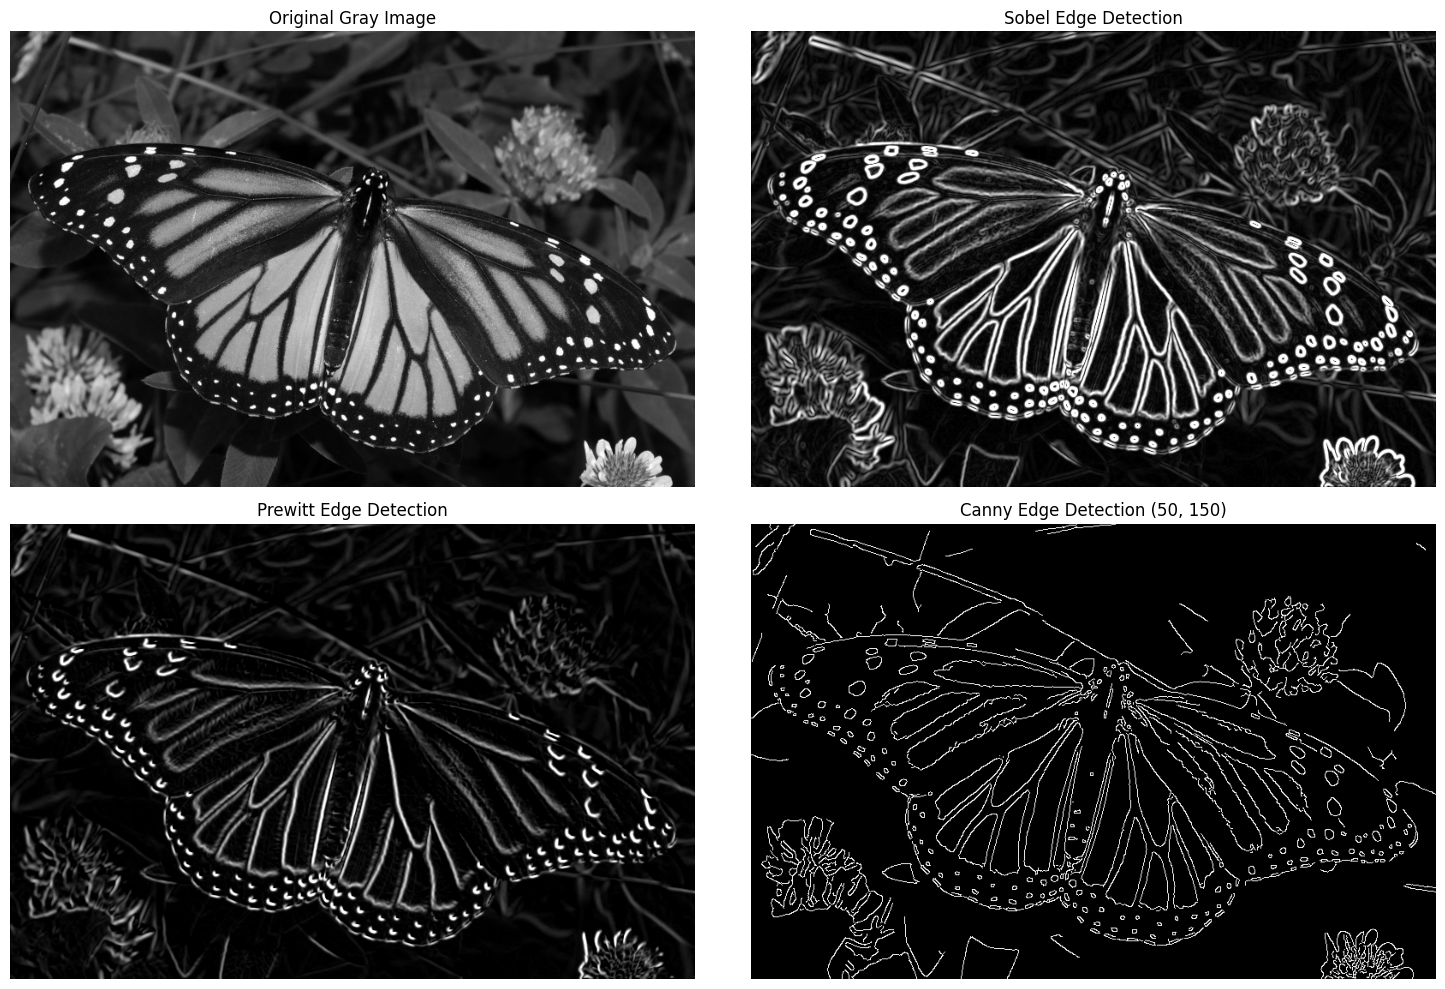

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image in grayscale
img_path = '/content/Butterfly.jpg'
image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(f"Could not load image at {img_path}. Please check if the file exists.")

# Apply Gaussian Blur to reduce noise before edge detection
blurred_image = cv2.GaussianBlur(image, (5, 5), 0)

# 1. Sobel Edge Detector
sobel_x = cv2.Sobel(blurred_image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred_image, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobel_x, sobel_y)
sobel_magnitude = np.uint8(np.clip(sobel_combined, 0, 255))

# 2. Prewitt Edge Detector (Using manual kernels)
kernelx = np.array([[1,1,1],[0,0,0],[-1,-1,-1]], dtype=np.float32)
kernely = np.array([[-1,0,1],[-1,0,1],[-1,0,1]], dtype=np.float32)
prewitt_x = cv2.filter2D(blurred_image, -1, kernelx)
prewitt_y = cv2.filter2D(blurred_image, -1, kernely)
prewitt_combined = cv2.magnitude(prewitt_x.astype(float), prewitt_y.astype(float))
prewitt_magnitude = np.uint8(np.clip(prewitt_combined, 0, 255))

# 3. Canny Edge Detector (using standard 50, 150 thresholds for Task 1)
canny_edges = cv2.Canny(blurred_image, 50, 150)

# Plot Task 1 results
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Gray Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(prewitt_magnitude, cmap='gray')
plt.title('Prewitt Edge Detection')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection (50, 150)')
plt.axis('off')

plt.tight_layout()
plt.show()

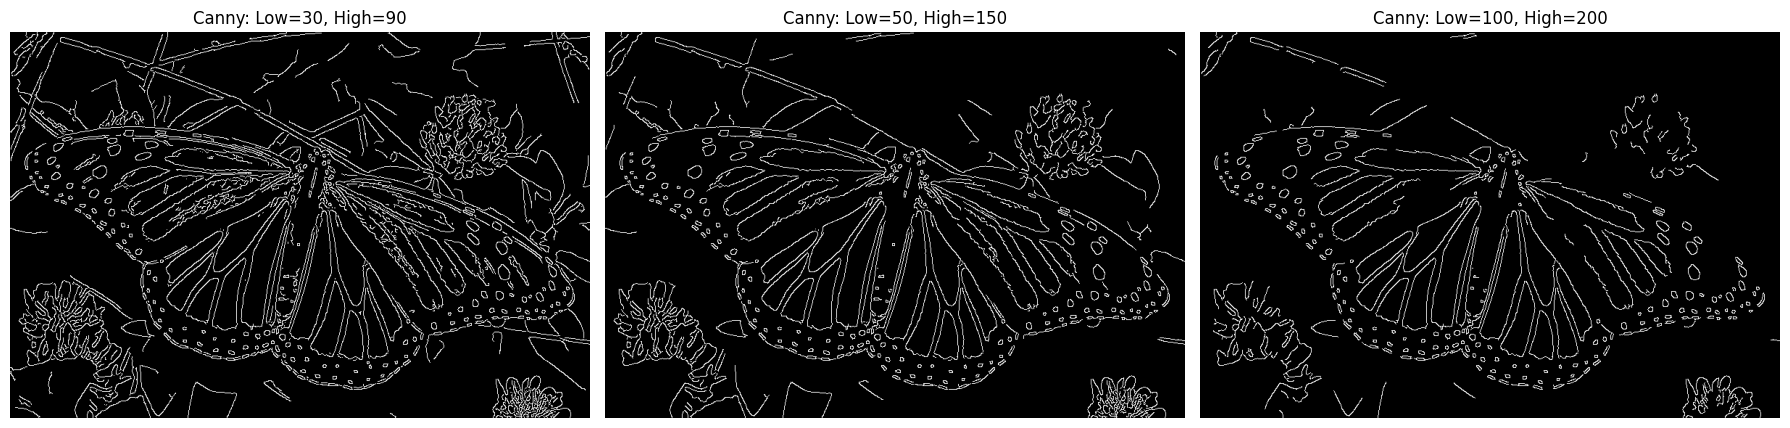

In [4]:
# Task 2: Investigate the Effect of Canny Thresholds
canny_1 = cv2.Canny(blurred_image, 30, 90)
canny_2 = cv2.Canny(blurred_image, 50, 150)
canny_3 = cv2.Canny(blurred_image, 100, 200)

# Display the three resulting edge maps side by side
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(canny_1, cmap='gray')
plt.title('Canny: Low=30, High=90')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(canny_2, cmap='gray')
plt.title('Canny: Low=50, High=150')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(canny_3, cmap='gray')
plt.title('Canny: Low=100, High=200')
plt.axis('off')

plt.tight_layout()
plt.show()

### Task 2 Discussion & Analysis

**How changing the thresholds affects the number of detected edges and the visibility of image details:**
- **Lower Thresholds (Low = 30, High = 90):**
  At lower threshold values, the detector is highly sensitive. As a result, it detects a significant amount of edges, capturing extremely fine details, textures, and even background noise. However, this can lead to a cluttered and noisy edge map where the main structural boundaries might be harder to distinguish.
  
- **Moderate Thresholds (Low = 50, High = 150):**
  This is a balanced threshold pair. It successfully preserves the prominent structural lines (strong edges) of the main subject while filtering out minor surface details and random noise, resulting in cleaner and more meaningful boundaries.

- **Higher Thresholds (Low = 100, High = 200):**
  At high thresholds, the algorithm is very strict, filtering out most variations. Only the strongest boundaries with high-intensity gradients (e.g., sharp boundaries between the subject and the background) are preserved. Consequently, many subtle details, textures, and weaker/finer edges are completely missed, leaving behind a sparse edge map.